In [1]:
import pandas as pd
df = pd.read_csv("loan.csv", nrows=50000)
df.shape

(50000, 145)

In [2]:
print([c in df.columns for c in ["loan_status", "loan_amnt", "int_rate", "grade", "dti", "annual_inc", "purpose"]])
print(df["loan_status"].value_counts())

df = df[df["loan_status"].isin(["Fully Paid", "Charged Off"])].copy()
df["default"] = (df["loan_status"] == "Charged Off").astype(int)

print("Rows kept:", len(df))
print("Default rate:", df["default"].mean())

[True, True, True, True, True, True, True]
loan_status
Current               48708
Fully Paid             1036
In Grace Period         113
Late (31-120 days)       86
Late (16-30 days)        54
Charged Off               3
Name: count, dtype: int64
Rows kept: 1039
Default rate: 0.0028873917228103944


In [3]:
import pandas as pd

wanted = ["loan_status", "loan_amnt", "term", "int_rate", "installment", "grade",
          "sub_grade", "emp_length", "home_ownership", "annual_inc",
          "verification_status", "issue_d", "purpose", "addr_state", "dti",
          "delinq_2yrs", "fico_range_low", "fico_range_high", "open_acc",
          "pub_rec", "revol_bal", "revol_util", "total_acc"]

chunks = []
for chunk in pd.read_csv("loan.csv", usecols=lambda c: c in wanted,
                         chunksize=200000, low_memory=False):
    chunks.append(chunk[chunk["loan_status"].isin(["Fully Paid", "Charged Off"])])

df = pd.concat(chunks, ignore_index=True)
df["default"] = (df["loan_status"] == "Charged Off").astype(int)

print(df.shape)
print(df["loan_status"].value_counts())
print("Default rate:", df["default"].mean())

(1303607, 22)
loan_status
Fully Paid     1041952
Charged Off     261655
Name: count, dtype: int64
Default rate: 0.2007161667588468


Missing: ['fico_range_low', 'fico_range_high']
grade
A    0.061
B    0.134
C    0.225
D    0.304
E    0.386
F    0.453
G    0.501
Name: default, dtype: float64
term
36 months    0.161
60 months    0.326
Name: default, dtype: float64
                     mean   count
purpose                          
small_business      0.297   15010
renewable_energy    0.237     911
moving              0.234    9172
medical             0.219   15023
house               0.217    6967
debt_consolidation  0.213  757591
other               0.212   74934
vacation            0.192    8732
major_purchase      0.187   28328
home_improvement    0.179   84495
educational         0.172     326
credit_card         0.170  285704
car                 0.146   14120
wedding             0.122    2294


<Axes: title={'center': 'Default rate by grade'}, xlabel='grade'>

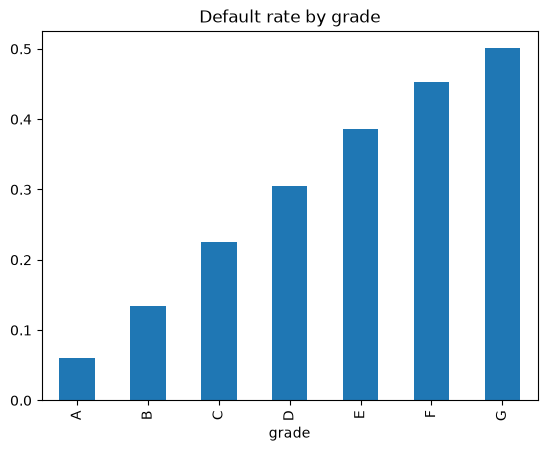

In [4]:
# which columns didn't load?
print("Missing:", [c for c in wanted if c not in df.columns])

# default rate by credit grade (A = safest, G = riskiest)
print(df.groupby("grade")["default"].mean().round(3))

# default rate by loan term
print(df.groupby("term")["default"].mean().round(3))

# default rate by purpose, with counts
print(df.groupby("purpose")["default"].agg(["mean", "count"]).sort_values("mean", ascending=False).round(3))

# chart
df.groupby("grade")["default"].mean().plot(kind="bar", title="Default rate by grade")

In [5]:
# which columns have missing values (% of rows)
print((df.isnull().mean() * 100).round(1).sort_values(ascending=False).head(8))

# default rate by quintile (5 equal-sized buckets) of each numeric feature
for col in ["int_rate", "dti", "annual_inc", "loan_amnt"]:
    bins = pd.qcut(df[col], 5, duplicates="drop")
    print("\n", col)
    print(df.groupby(bins, observed=True)["default"].mean().round(3))

emp_length     5.8
revol_util     0.1
int_rate       0.0
installment    0.0
loan_amnt      0.0
term           0.0
sub_grade      0.0
grade          0.0
dtype: float64

 int_rate
int_rate
(5.308999999999999, 8.9]    0.068
(8.9, 11.53]                0.139
(11.53, 13.99]              0.195
(13.99, 16.99]              0.251
(16.99, 30.99]              0.360
Name: default, dtype: float64

 dti
dti
(-1.001, 10.48]    0.149
(10.48, 15.32]     0.168
(15.32, 19.97]     0.192
(19.97, 25.66]     0.221
(25.66, 999.0]     0.273
Name: default, dtype: float64

 annual_inc
annual_inc
(-0.001, 42000.0]         0.237
(42000.0, 57000.0]        0.217
(57000.0, 74000.0]        0.204
(74000.0, 100000.0]       0.185
(100000.0, 10999200.0]    0.158
Name: default, dtype: float64

 loan_amnt
loan_amnt
(499.999, 6500.0]     0.160
(6500.0, 10000.0]     0.177
(10000.0, 15000.0]    0.209
(15000.0, 21000.0]    0.228
(21000.0, 40000.0]    0.235
Name: default, dtype: float64


In [6]:
# text -> numbers
df["term_months"] = df["term"].str.extract(r"(\d+)")[0].astype(int)
df["emp_years"] = df["emp_length"].str.extract(r"(\d+)")[0].astype(float)
df.loc[df["emp_length"] == "< 1 year", "emp_years"] = 0

# tame outliers
df["dti"] = df["dti"].clip(0, 60)
df["annual_inc"] = df["annual_inc"].clip(upper=df["annual_inc"].quantile(0.99))

# fill the few missing values with the median
for c in ["emp_years", "revol_util", "dti"]:
    df[c] = df[c].fillna(df[c].median())

# loan year, for the train/test split later
df["issue_year"] = pd.to_datetime(df["issue_d"], format="%b-%Y").dt.year

print(df[["dti", "annual_inc", "emp_years", "term_months"]].describe().round(1))
print(df.groupby("issue_year")["default"].agg(["mean", "count"]).round(3))

             dti  annual_inc  emp_years  term_months
count  1303607.0   1303607.0  1303607.0    1303607.0
mean        18.2     74499.2        6.0         41.8
std          8.6     42041.0        3.6         10.3
min          0.0         0.0        0.0         36.0
25%         11.8     45840.0        3.0         36.0
50%         17.6     65000.0        6.0         36.0
75%         24.0     90000.0       10.0         36.0
max         60.0    250000.0       10.0         60.0
             mean   count
issue_year               
2007        0.179     251
2008        0.158    1562
2009        0.126    4716
2010        0.129   11536
2011        0.152   21721
2012        0.162   53367
2013        0.156  134793
2014        0.185  221468
2015        0.202  373412
2016        0.243  274699
2017        0.229  158900
2018        0.147   47182


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score

d = df[df["issue_year"] <= 2017].copy()
d["revol_bal"] = d["revol_bal"].clip(upper=d["revol_bal"].quantile(0.99))
train = d[d["issue_year"] <= 2015]
test = d[d["issue_year"] >= 2016]

num = ["loan_amnt", "term_months", "annual_inc", "dti", "emp_years",
       "delinq_2yrs", "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc"]
cat = ["home_ownership", "verification_status", "purpose"]

def run(num_cols, cat_cols):
    pre = ColumnTransformer([("n", StandardScaler(), num_cols),
                             ("c", OneHotEncoder(handle_unknown="ignore"), cat_cols)])
    m = Pipeline([("pre", pre), ("lr", LogisticRegression(max_iter=200))])
    m.fit(train[num_cols + cat_cols], train["default"])
    p = m.predict_proba(test[num_cols + cat_cols])[:, 1]
    return roc_auc_score(test["default"], p)

print("Train rows:", len(train), "| Test rows:", len(test))
print("Model A (borrower features only) AUC:", round(run(num, cat), 3))
print("Model B (+ grade, int_rate, installment) AUC:", round(run(num + ["int_rate", "installment"], cat + ["grade"]), 3))

Train rows: 822826 | Test rows: 433599
Model A (borrower features only) AUC: 0.665
Model B (+ grade, int_rate, installment) AUC: 0.698


In [8]:
def fit_predict(num_cols, cat_cols):
    pre = ColumnTransformer([("n", StandardScaler(), num_cols),
                             ("c", OneHotEncoder(handle_unknown="ignore"), cat_cols)])
    m = Pipeline([("pre", pre), ("lr", LogisticRegression(max_iter=200))])
    m.fit(train[num_cols + cat_cols], train["default"])
    return m.predict_proba(test[num_cols + cat_cols])[:, 1]

test = test.copy()
test["score_A"] = fit_predict(num, cat)
test["score_B"] = fit_predict(num + ["int_rate", "installment"], cat + ["grade"])

total_def = test["default"].sum()
total_good = (1 - test["default"]).sum()
rows = []
for name in ["score_A", "score_B"]:
    for rej in [0.10, 0.20, 0.30, 0.40]:
        cut = test[name].quantile(1 - rej)
        approved = test[test[name] <= cut]
        rejected = test[test[name] > cut]
        rows.append({
            "model": name[-1],
            "reject_%": int(rej * 100),
            "default_rate_of_approved": round(approved["default"].mean(), 3),
            "defaults_avoided_%": round(rejected["default"].sum() / total_def * 100, 1),
            "good_loans_rejected_%": round((1 - rejected["default"]).sum() / total_good * 100, 1),
        })

print("Default rate if we approve everyone:", round(test["default"].mean(), 3))
print(pd.DataFrame(rows).to_string(index=False))

Default rate if we approve everyone: 0.238
model  reject_%  default_rate_of_approved  defaults_avoided_%  good_loans_rejected_%
    A        10                     0.213                19.3                    7.1
    A        20                     0.198                33.4                   15.8
    A        30                     0.182                46.3                   24.9
    A        40                     0.167                57.9                   34.4
    B        10                     0.210                20.5                    6.7
    B        20                     0.189                36.3                   14.9
    B        30                     0.171                49.6                   23.9
    B        40                     0.152                61.6                   33.3


In [9]:
pd.DataFrame(rows).to_csv("cutoff_results.csv", index=False)

for col in ["grade", "term", "purpose", "issue_year"]:
    df.groupby(col)["default"].agg(["mean", "count"]).reset_index().to_csv(f"by_{col}.csv", index=False)

out = []
for col in ["int_rate", "dti", "annual_inc", "loan_amnt"]:
    b = pd.qcut(df[col], 5, duplicates="drop")
    t = df.groupby(b, observed=True)["default"].mean().reset_index()
    t.columns = ["bucket", "default_rate"]
    t["bucket"] = t["bucket"].astype(str)
    t["feature"] = col
    out.append(t)
pd.concat(out).to_csv("by_feature_quintile.csv", index=False)

print("saved")

saved


In [10]:
import sqlite3
con = sqlite3.connect("loans.db")
df.rename(columns={"default": "is_default"}).to_sql("loans", con, if_exists="replace", index=False, chunksize=100000)
print(pd.read_sql_query("SELECT COUNT(*) AS n FROM loans", con))

         n
0  1303607


In [11]:
q1 = """
SELECT grade, COUNT(*) AS loans, ROUND(AVG(is_default), 3) AS default_rate
FROM loans
GROUP BY grade
ORDER BY grade
"""

q2 = """
SELECT CASE WHEN dti < 10 THEN '1. under 10'
            WHEN dti < 20 THEN '2. 10-20'
            WHEN dti < 30 THEN '3. 20-30'
            ELSE '4. 30+' END AS dti_band,
       COUNT(*) AS loans,
       ROUND(AVG(is_default), 3) AS default_rate
FROM loans
GROUP BY dti_band
ORDER BY dti_band
"""

q3 = """
SELECT purpose, term_months, COUNT(*) AS loans, ROUND(AVG(is_default), 3) AS default_rate
FROM loans
GROUP BY purpose, term_months
HAVING COUNT(*) > 5000
ORDER BY default_rate DESC
LIMIT 10
"""

for q in [q1, q2, q3]:
    print(pd.read_sql_query(q, con))
    print()

  grade   loans  default_rate
0     A  226243         0.061
1     B  380152         0.134
2     C  369928         0.225
3     D  195280         0.304
4     E   91570         0.386
5     F   31483         0.453
6     G    8951         0.501

      dti_band   loans  default_rate
0  1. under 10  238193         0.149
1     2. 10-20  545304         0.179
2     3. 20-30  396265         0.232
3       4. 30+  123845         0.295

              purpose  term_months   loans  default_rate
0               other           60   11846         0.356
1      major_purchase           60    5740         0.335
2  debt_consolidation           60  204277         0.334
3         credit_card           60   59965         0.303
4    home_improvement           60   20987         0.280
5      small_business           36   11506         0.257
6              moving           36    8151         0.214
7             medical           36   12791         0.198
8               house           36    5118         0.186
9  